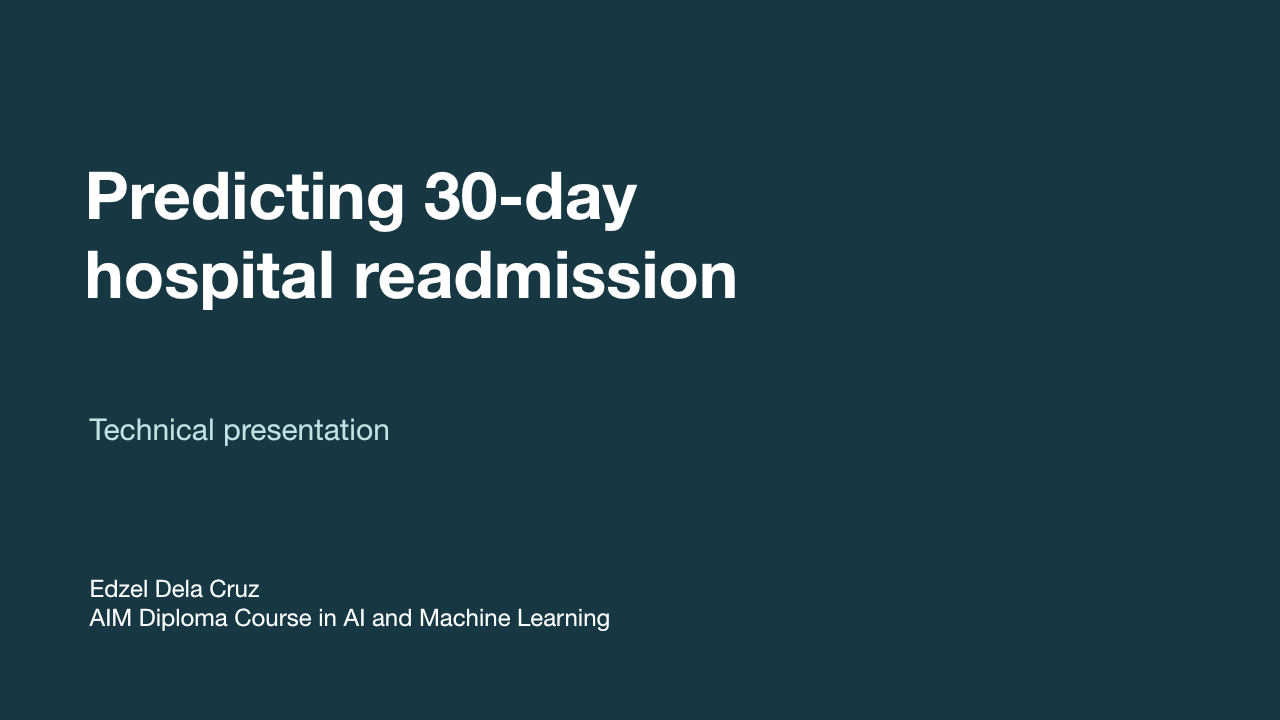

### Presenter notes

Dataset: Clore et al. (2014), UCI Diabetes 130-US Hospitals (1999–2008). https://doi.org/10.24432/C5230J
Source: notebooks 01–06 and saved reports in AIM_Capstone. Results verified 13 October 2026.



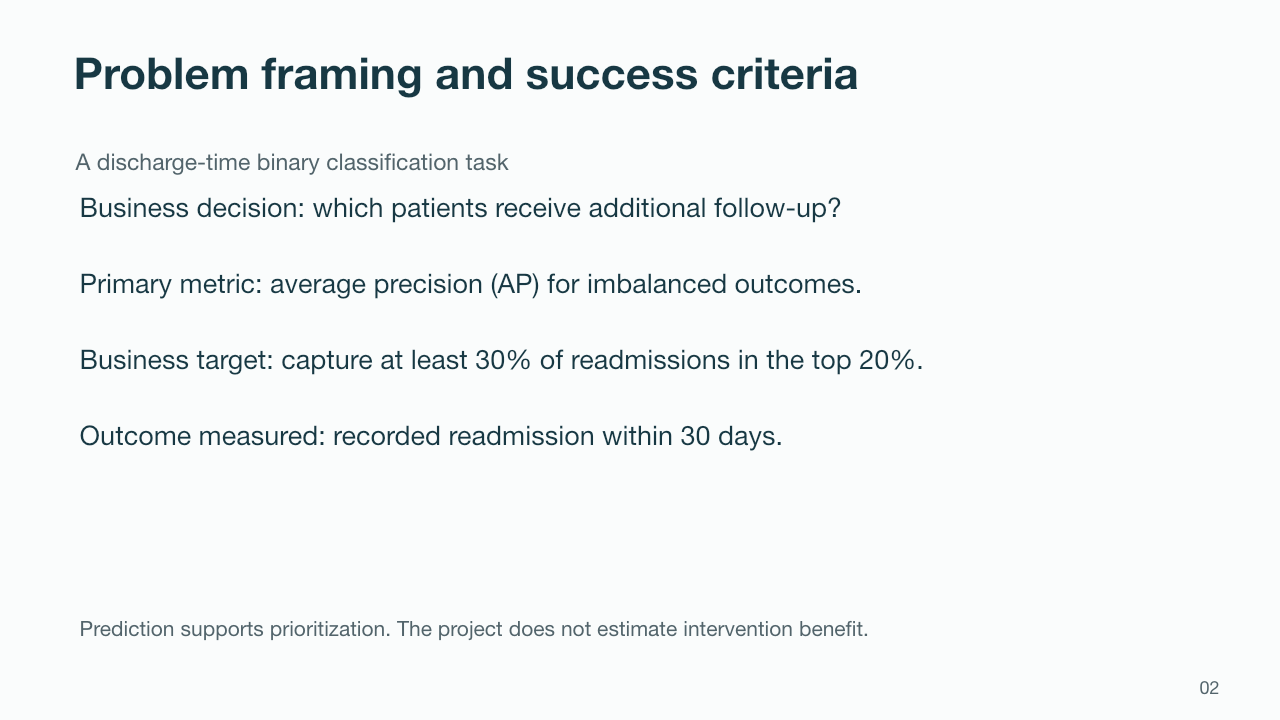

### Presenter notes

Dataset: Clore et al. (2014), UCI Diabetes 130-US Hospitals (1999–2008). https://doi.org/10.24432/C5230J
Classification target: readmitted == <30. Discharge-time predictors. AP is sklearn average_precision_score, not trapezoidal PR-AUC.

Primary metric: AP. Secondary: ROC-AUC, precision, recall and workload.
Business target: top-20% capture ≥30%.

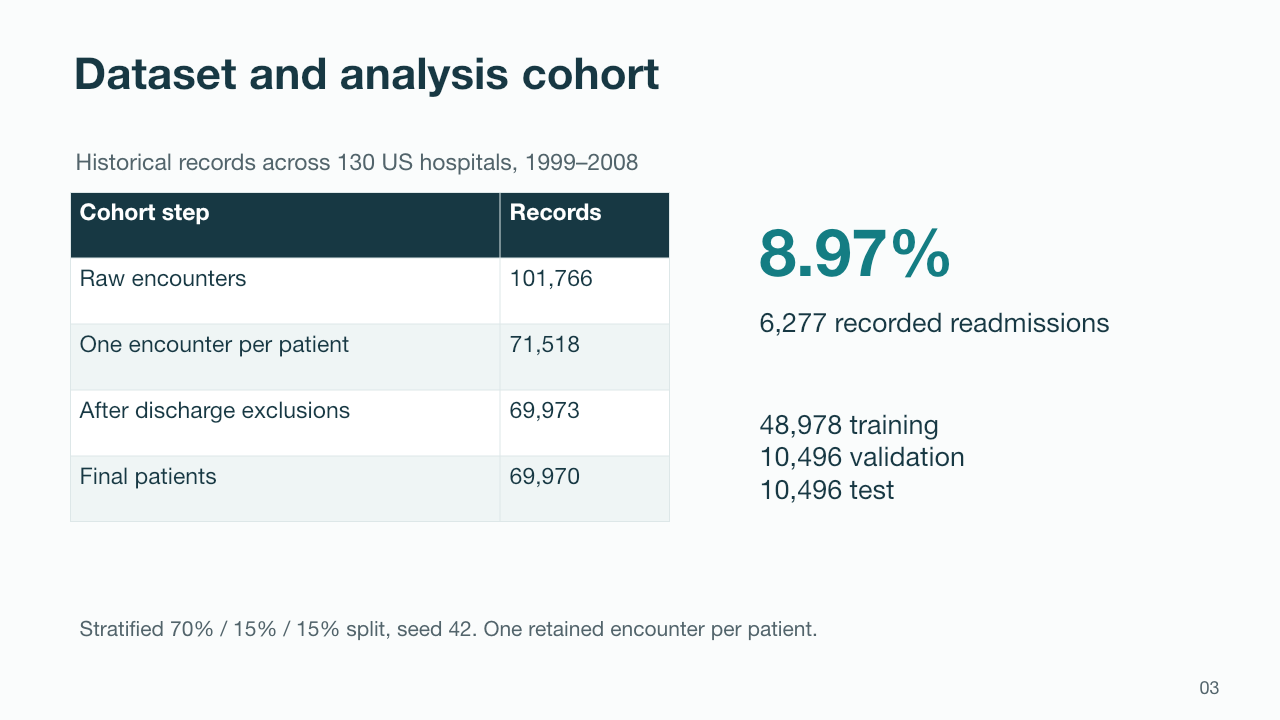

### Presenter notes

Dataset: Clore et al. (2014), UCI Diabetes 130-US Hospitals (1999–2008). https://doi.org/10.24432/C5230J
Cohort order: one encounter by lowest encounter_id, excluded codes 11,13,14,19,20,21, then invalid gender. IDs approximate chronology.

101,766 encounters → 69,970 patients. 6,277 positives (8.97%).
Training 48,978. Validation 10,496. Test 10,496.

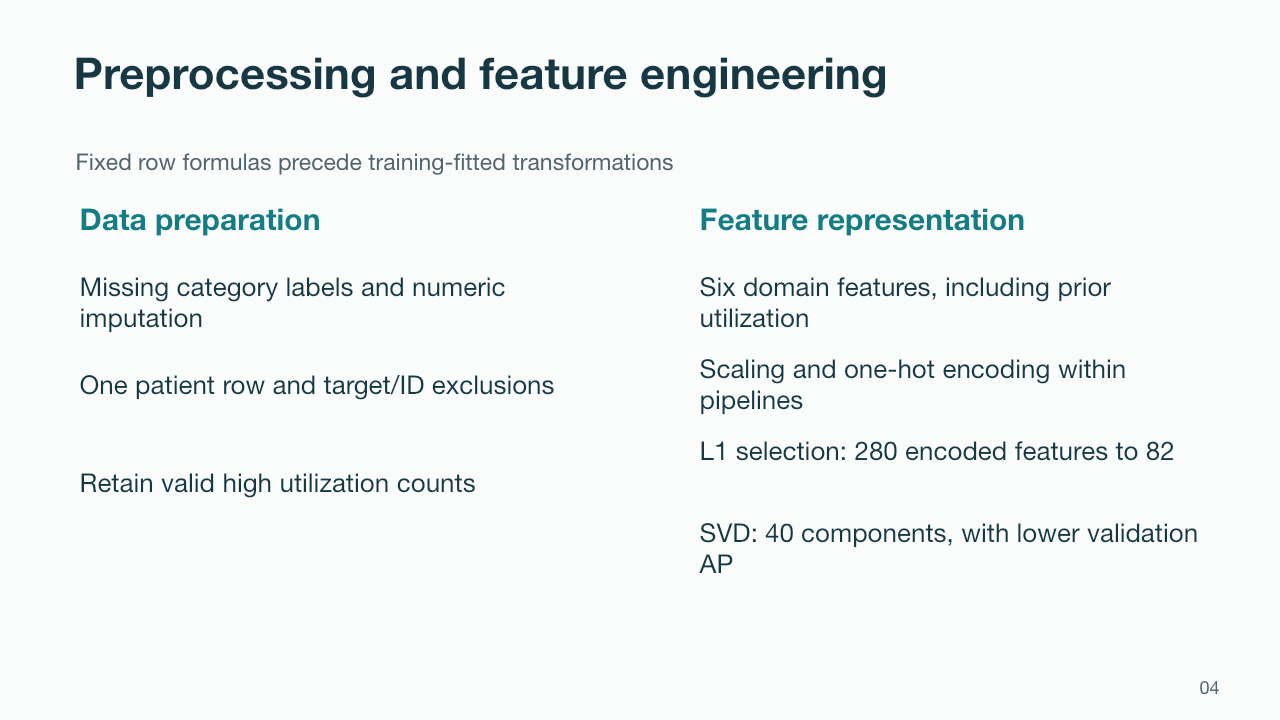

### Presenter notes

Sources: 02_data_cleaning_split.ipynb, 03_eda.ipynb, 04_feature_engineering.ipynb, Data_Dictionary.md. Rare-medication exclusions used full-cohort frequencies and remain a limitation.

Train-fitted median imputation, scaling and encoding.
Six domain features. Embedded L1 selection. Sparse-compatible SVD.
Outliers retained where clinically plausible. Rare-column exclusion limitation disclosed.

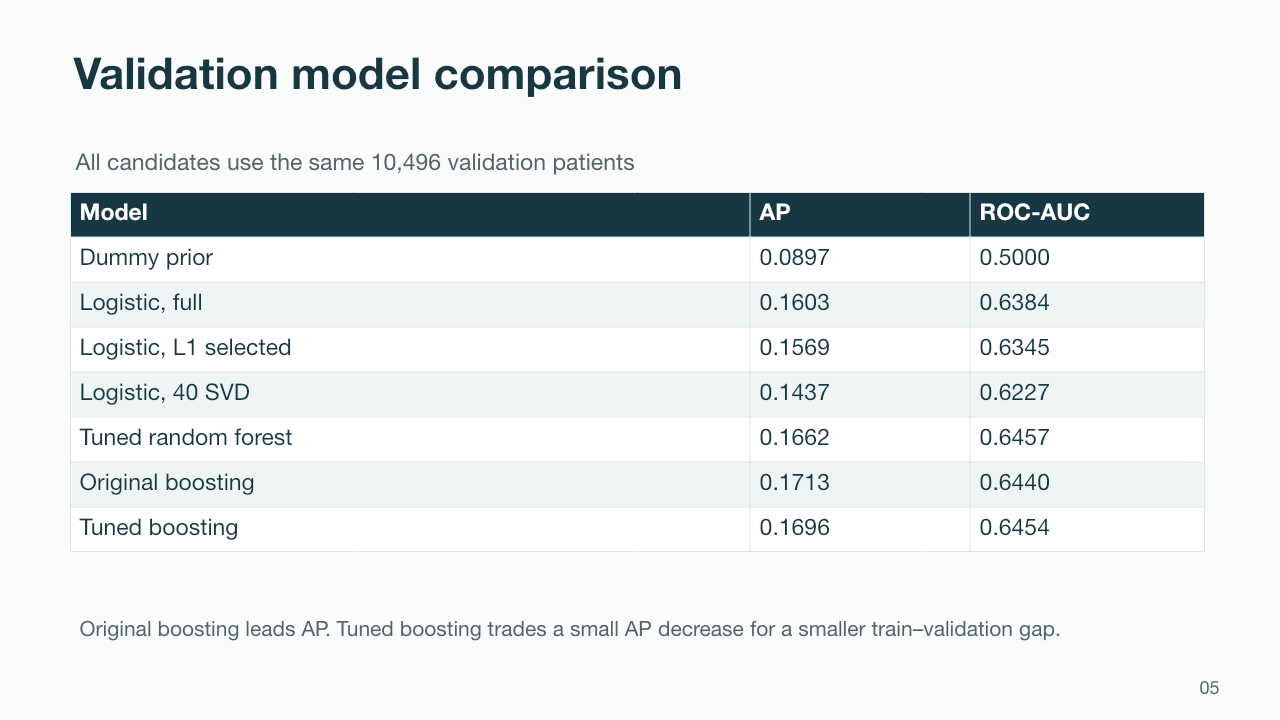

### Presenter notes

Sources: 05_model_evaluation.ipynb and reports/significance_analysis/validation_metrics.csv. AP is primary. Three-fold stratified training CV tunes tree models. RF winner depth12, minimum leaf10. Boosting winner leaf7, L2=1.0.

Model: AP: ROC-AUC
Dummy prior: 0.0897: 0.5000
Logistic, full: 0.1603: 0.6384
Logistic, L1 selected: 0.1569: 0.6345
Logistic, 40 SVD: 0.1437: 0.6227
Tuned random forest: 0.1662: 0.6457
Original boosting: 0.1713: 0.6440
Tuned boosting: 0.1696: 0.6454

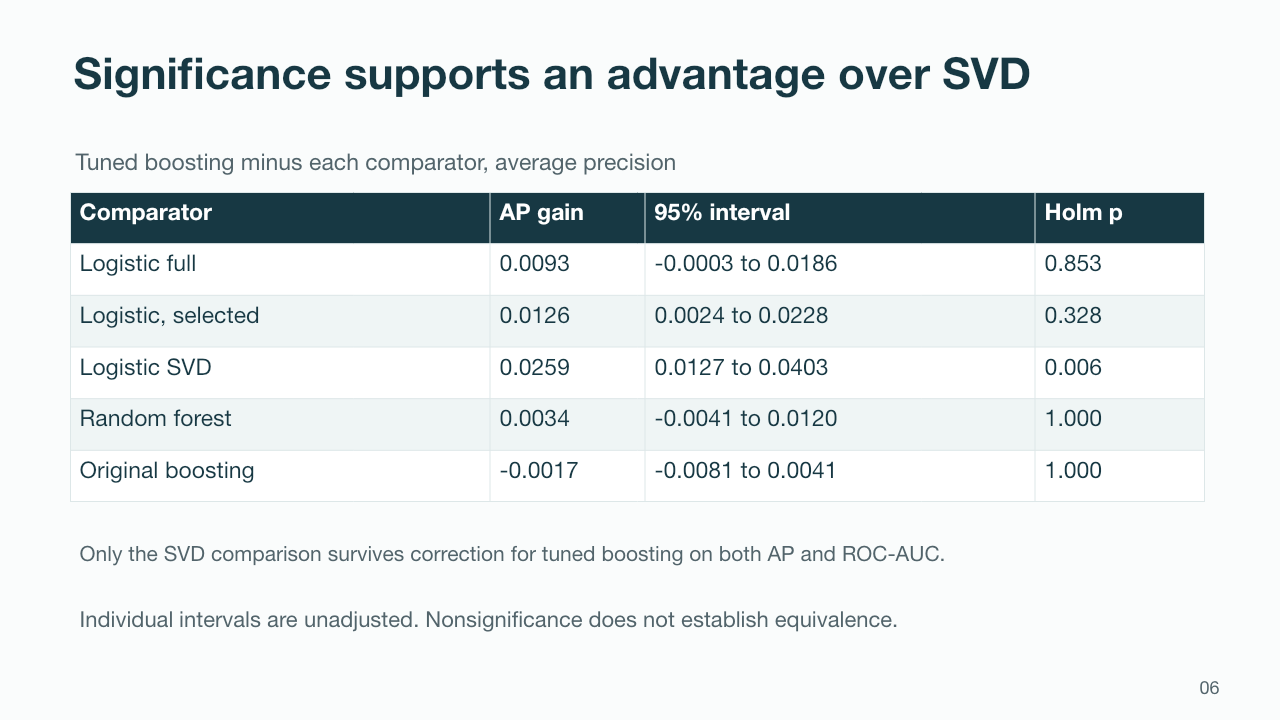

### Presenter notes

Sources: reports/significance_analysis/pairwise_tests.csv and notebook05. 5,000 paired stratified AP bootstrap samples, percentile individual CIs, approximate two-sided normal bootstrap-SE tests. Paired DeLong AUC tests (https://pubmed.ncbi.nlm.nih.gov/3203132/). Holm correction across 15 learned-model pairs ×2 metrics. Exploratory post-selection comparisons.

Comparator: AP gain: 95% interval: Holm p
Logistic full: 0.0093: -0.0003 to 0.0186: 0.853
Logistic, selected: 0.0126: 0.0024 to 0.0228: 0.328
Logistic SVD: 0.0259: 0.0127 to 0.0403: 0.006
Random forest: 0.0034: -0.0041 to 0.0120: 1.000
Original boosting: -0.0017: -0.0081 to 0.0041: 1.000

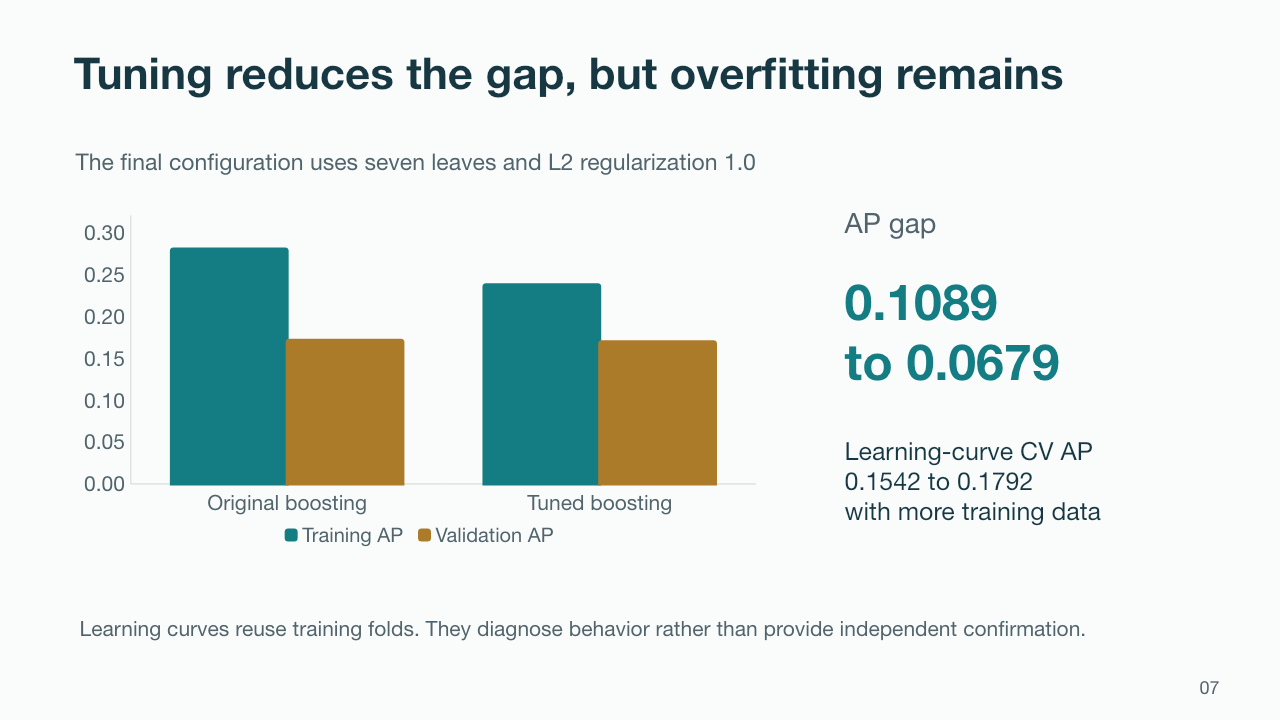

### Presenter notes

Sources: notebook05 train AP 0.2802 original,0.2375 tuned. Tuned learning curve CSV. Final settings: max_leaf_nodes7,l2_regularization1.0,learning_rate0.1,max_iter200,min_samples_leaf25,early_stoppingTrue,random_state42. CV3.

Original training–validation AP gap 0.1089. Tuned gap0.0679.
Final HGB configuration: leaf7, L2=1, learning rate0.1, iterations200, min leaf25, early stopping, seed42.

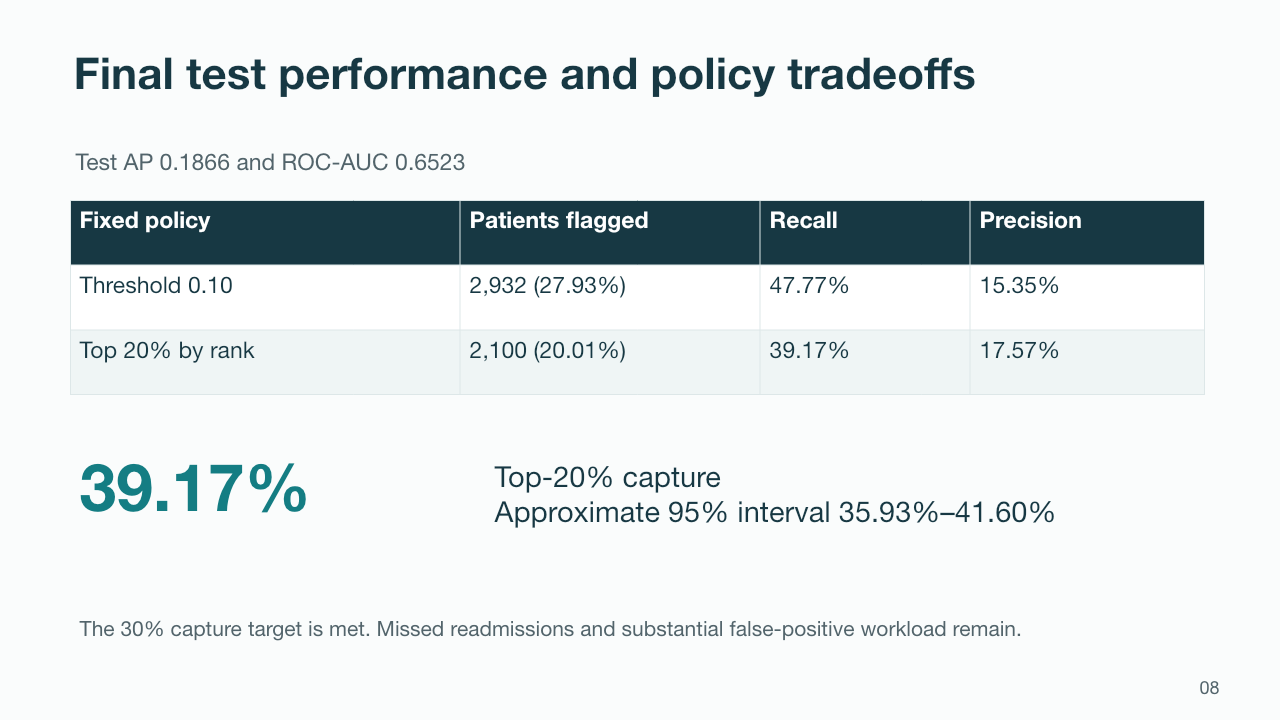

### Presenter notes

Sources: final_gradient_boosting_test_metrics.csv, policy_comparison.csv,test_bootstrap_intervals.csv. 300 fixed-model test bootstrap samples. Top20 ranking reranked in each sample.

Threshold0.10: recall47.77%, precision15.35%,2,932 flagged.
Top20: recall39.17%, precision17.57%,2,100 flagged. CaptureCI35.93–41.60%.

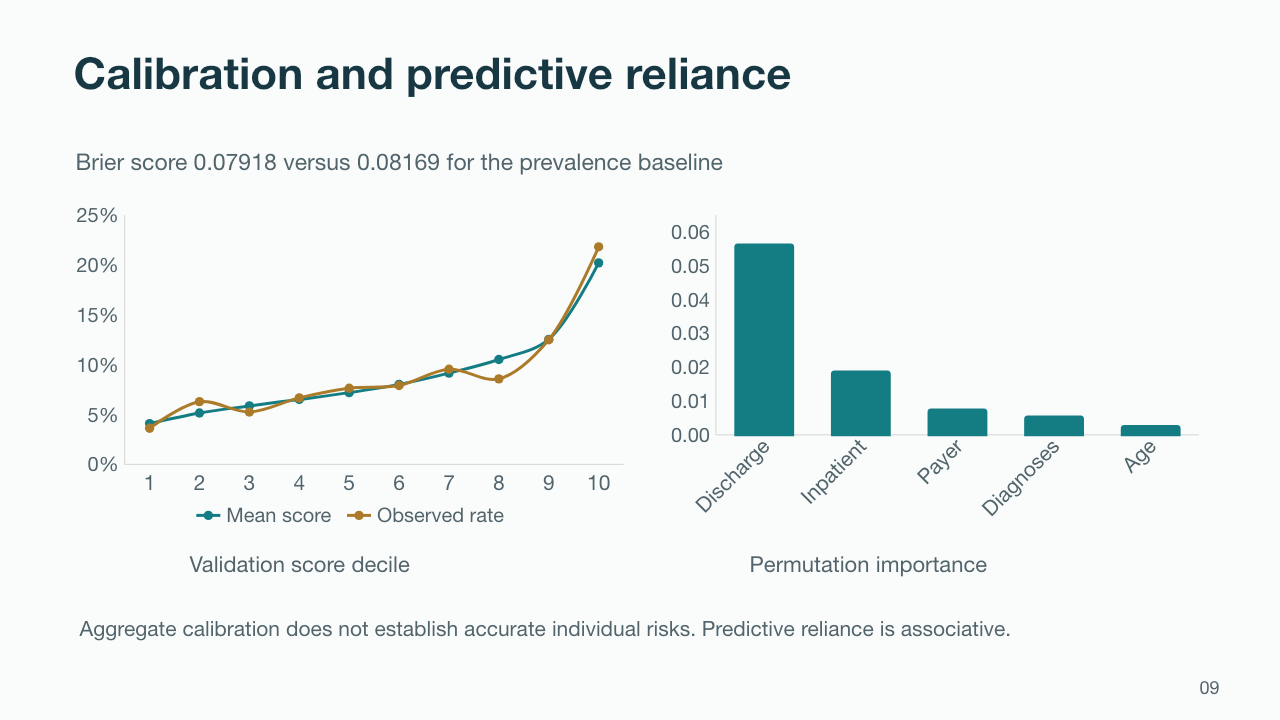

### Presenter notes

Sources: validation_calibration_bins.csv, validation_calibration_metrics.csv, validation_permutation_importance.csv. Five permutations per input column. SD measures shuffle variability, not CI.

Brier0.07918 versus prevalence0.08169.
Discharge disposition, inpatient visits and payer rank highest by permutation importance.

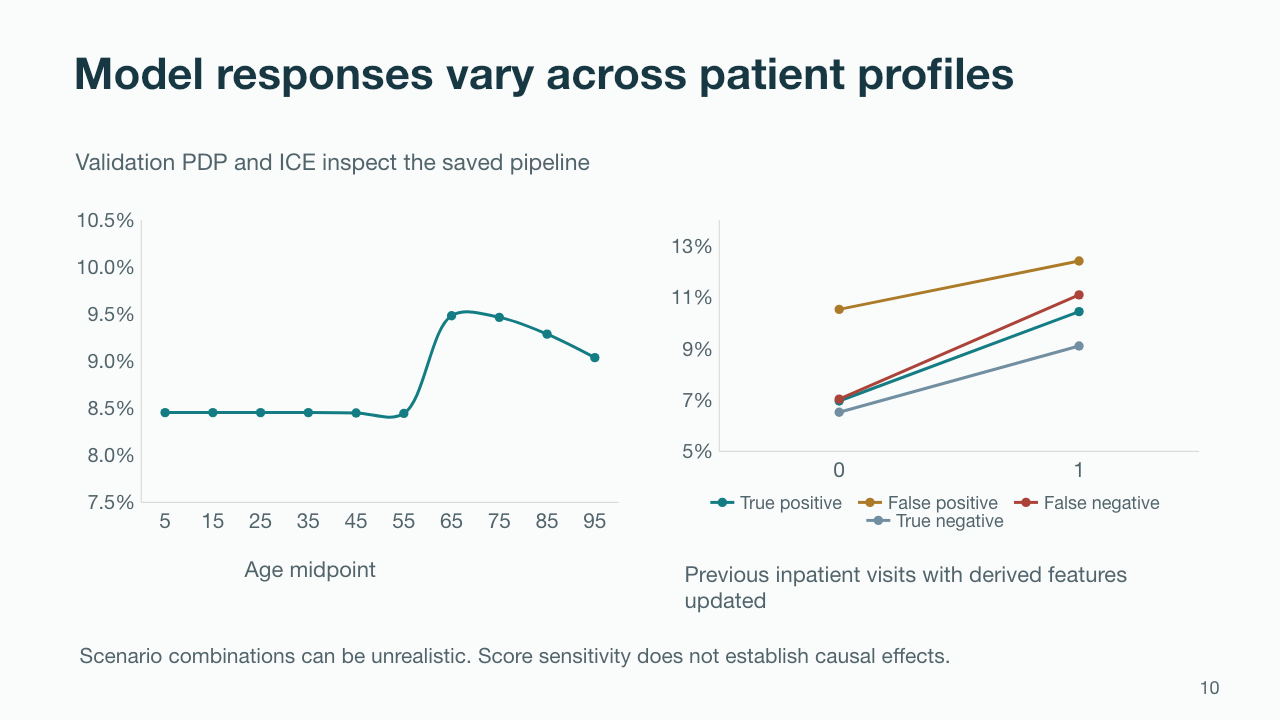

### Presenter notes

Sources: numeric_dependence.csv and representative_ice.csv. Background about1000 validation patients,60 ICE traces. Below: mean age PDP and coherent prior-inpatient scenario with representative profiles. Updating inpatient count also updates prior_inpatient and prior_utilization. Profiles nearest median score in each outcome class.

PDP/ICE uses validation profiles, with deterministic derived features kept coherent.
Individual profile sensitivity is not additive attribution or a causal explanation.

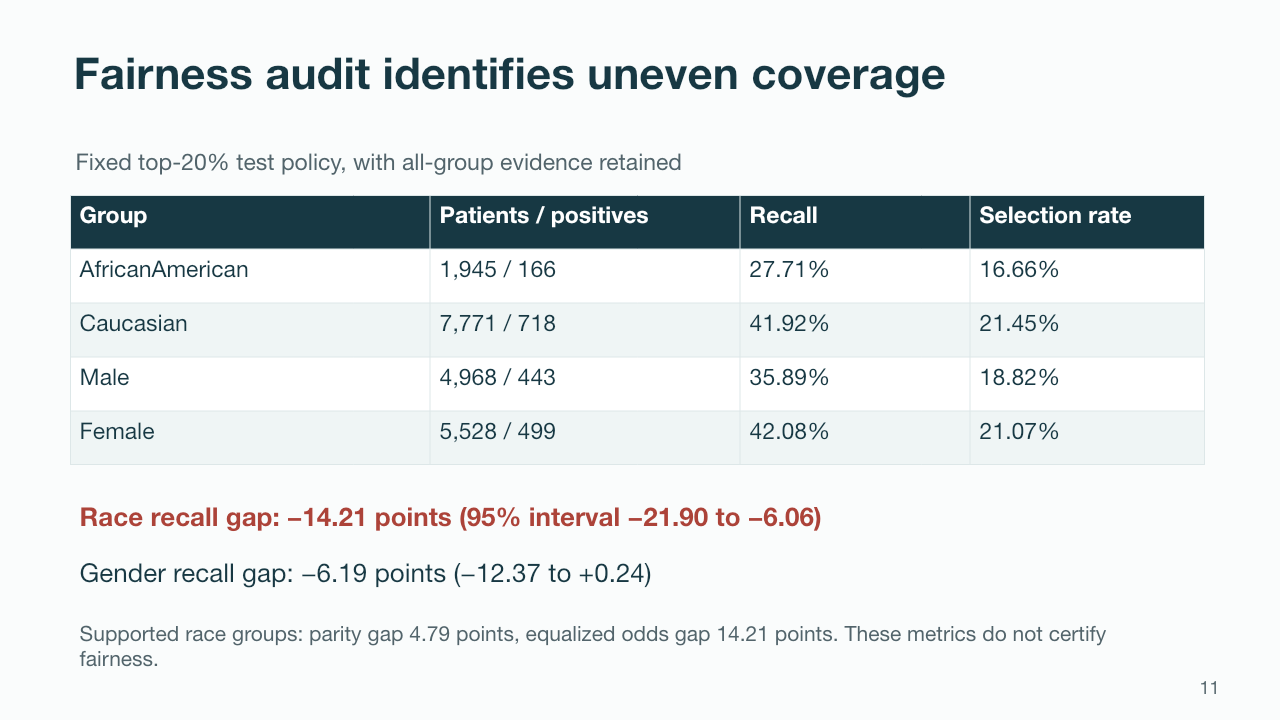

### Presenter notes

Sources: group_confusion_rates.csv,reference_contrasts.csv,parity_summary.csv. Fixed top20 test policy. Reported contrasts individual unadjusted2,000 bootstrap CIs. Supported groupsN>=100 positives>=30 negatives>=30; all groups retained in CSV. Payer insurance proxy not income.

Race TPRgap−14.21pp CI−21.90to−6.06. Gender−6.19pp CI−12.37to+.24.
Audit: demographic parity, equal opportunity, FPR, equalized odds; age, payer and intersections.

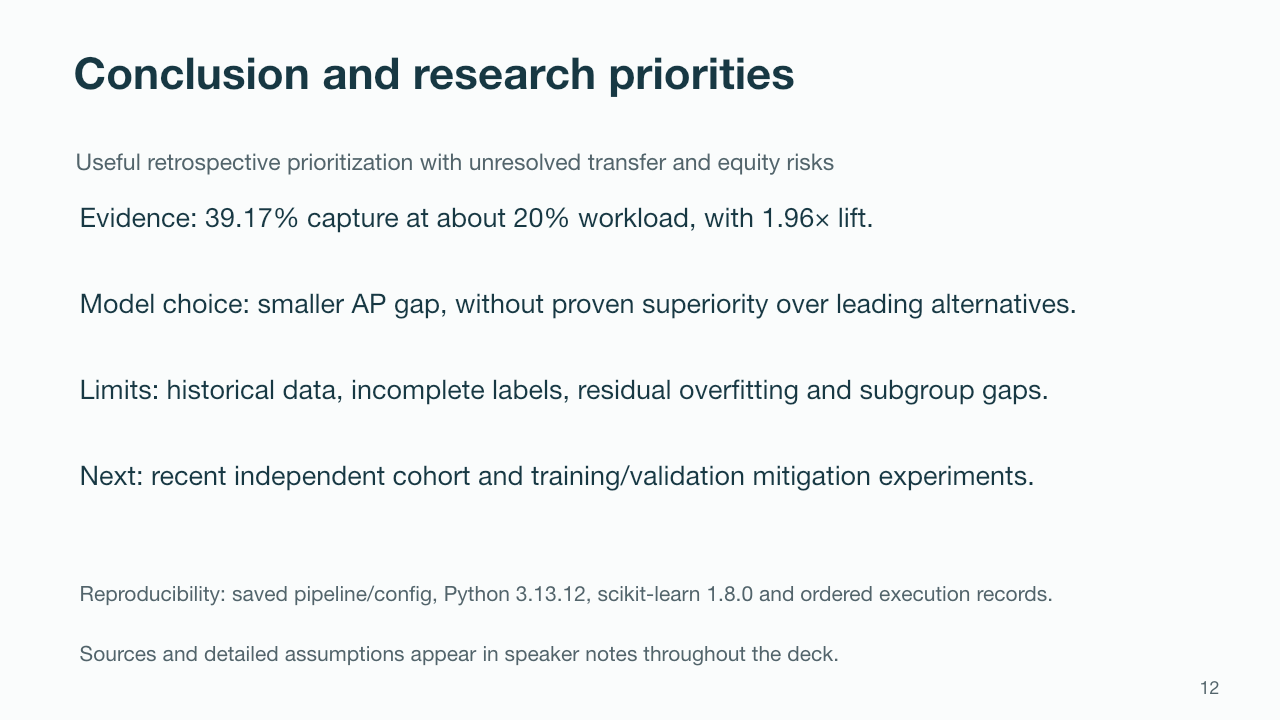

### Presenter notes

Sources: notebook06, README,requirements.txt,reports/reproducibility/verification_checks.json. Six notebooks157 code cells verified with fresh IPython processes. Eight identity matches ambiguous. No public GitHub URL verified. Mitigations proposed not implemented.

Fixed-model evidence supports retrospective prioritization.
External and intervention validation remain future work.
All six notebooks executed in order. Saved model,configs and requirements documented.